

## MODEL TRANING

In [42]:
# Local Heterogeneous Encoders (in_features -> 128):

# Client 1 (UNSW-NB15): 1D-Convolutional Neural Network (1D-CNN) — extracts local spatial correlations across NetFlow fields and projects to 128.

# Client 2 (ToN-IoT): Bidirectional GRU (BiGRU) — models sequential dependencies across flow features and projects to 128.

# Client 3 (CIC-IDS2018): Deep Residual MLP (ResNet-MLP) — uses skip connections to learn nonlinear tabular interactions and projects to 128.

# Shared Federated Head (128 -> 64 -> 4):

# All three clients feed their 128-d latent vector into an identical SharedGlobalHead.

# During each Federated Round, only the SharedGlobalHead parameters are aggregated on the server via FedProx,
# forcing all three heterogeneous encoders to align their 128-d latent spaces into a single universal intrusion manifold.

Running Heterogeneous Federated Learning on device: cuda

--- Loading & Splitting All 3 Client Datasets ---
[UNSW-NB15] Total Cols=32 | Input Features=29 | Train=115,500, Val=24,750, Test=24,750
[ToN-IoT] Total Cols=32 | Input Features=29 | Train=168,000, Val=36,000, Test=36,000
[CICIDS2018] Total Cols=32 | Input Features=29 | Train=179,900, Val=38,550, Test=38,550

 STARTING HETEROGENEOUS FEDERATED LEARNING (1D-CNN + BiGRU + ResMLP)
Round [01/15] | Global Avg Val Acc: 79.02% | Global Macro-F1: 0.7261 | UNSW F1: 0.6697 | ToN F1: 0.9301 | CIC F1: 0.5784
Round [02/15] | Global Avg Val Acc: 79.40% | Global Macro-F1: 0.7559 | UNSW F1: 0.6743 | ToN F1: 0.9446 | CIC F1: 0.6489
Round [03/15] | Global Avg Val Acc: 79.45% | Global Macro-F1: 0.7387 | UNSW F1: 0.6714 | ToN F1: 0.9484 | CIC F1: 0.5963
Round [04/15] | Global Avg Val Acc: 79.52% | Global Macro-F1: 0.7251 | UNSW F1: 0.6912 | ToN F1: 0.9550 | CIC F1: 0.5291
Round [05/15] | Global Avg Val Acc: 82.59% | Global Macro-F1: 0.7880 | UNSW F1

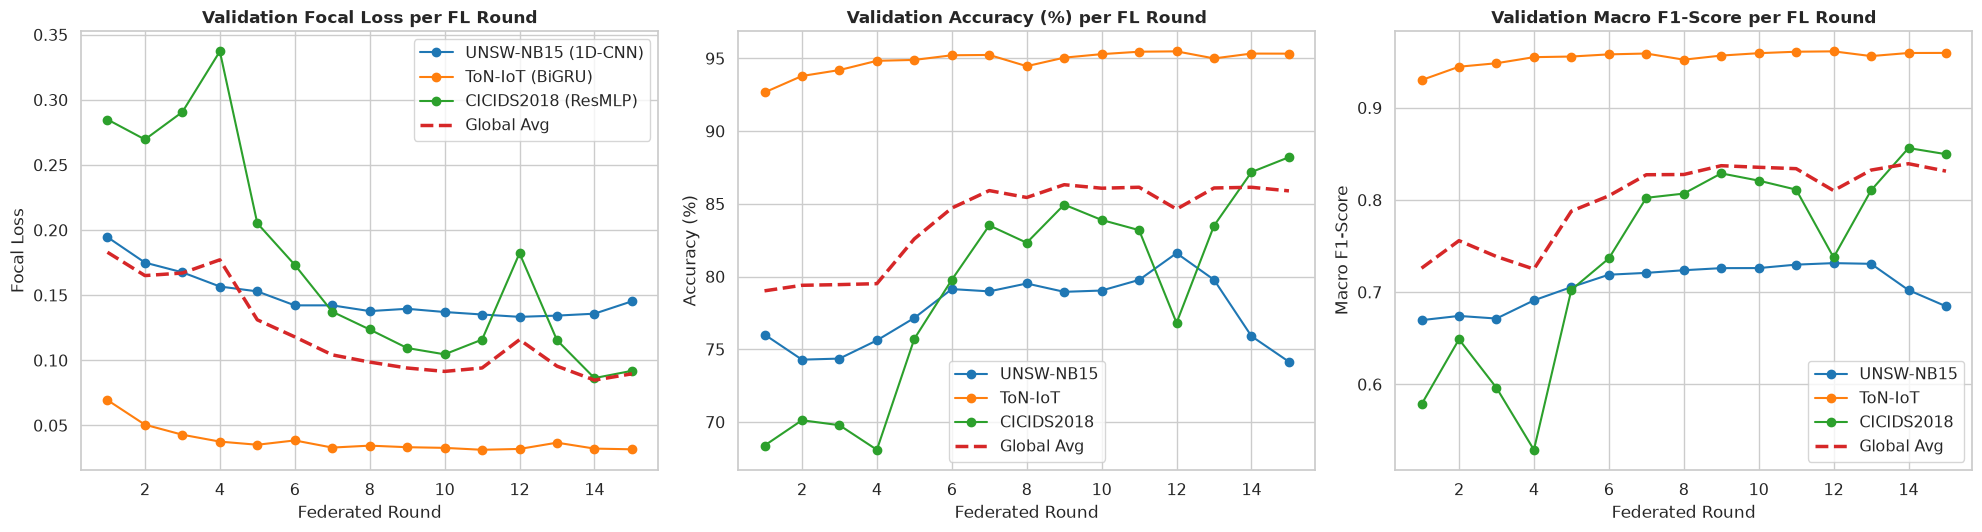

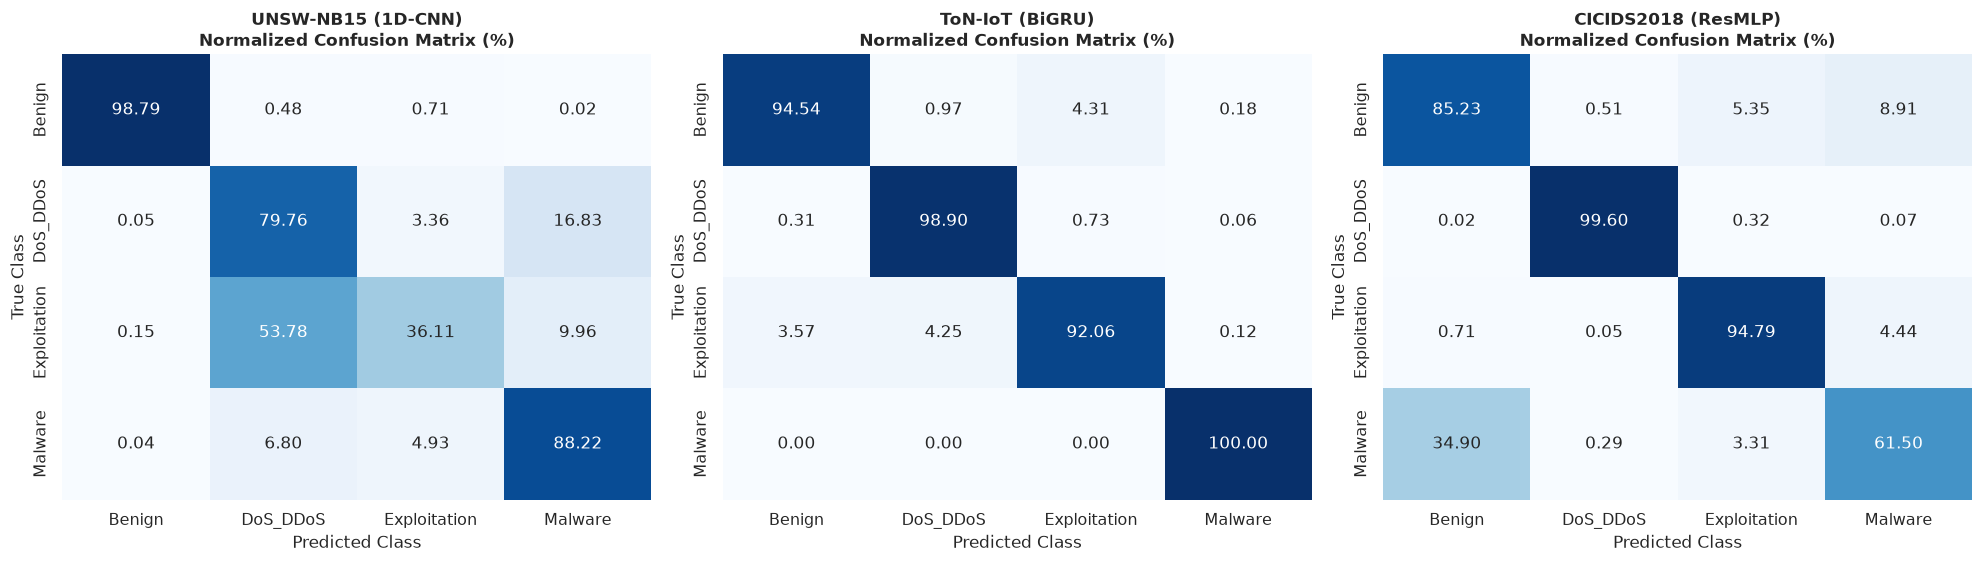

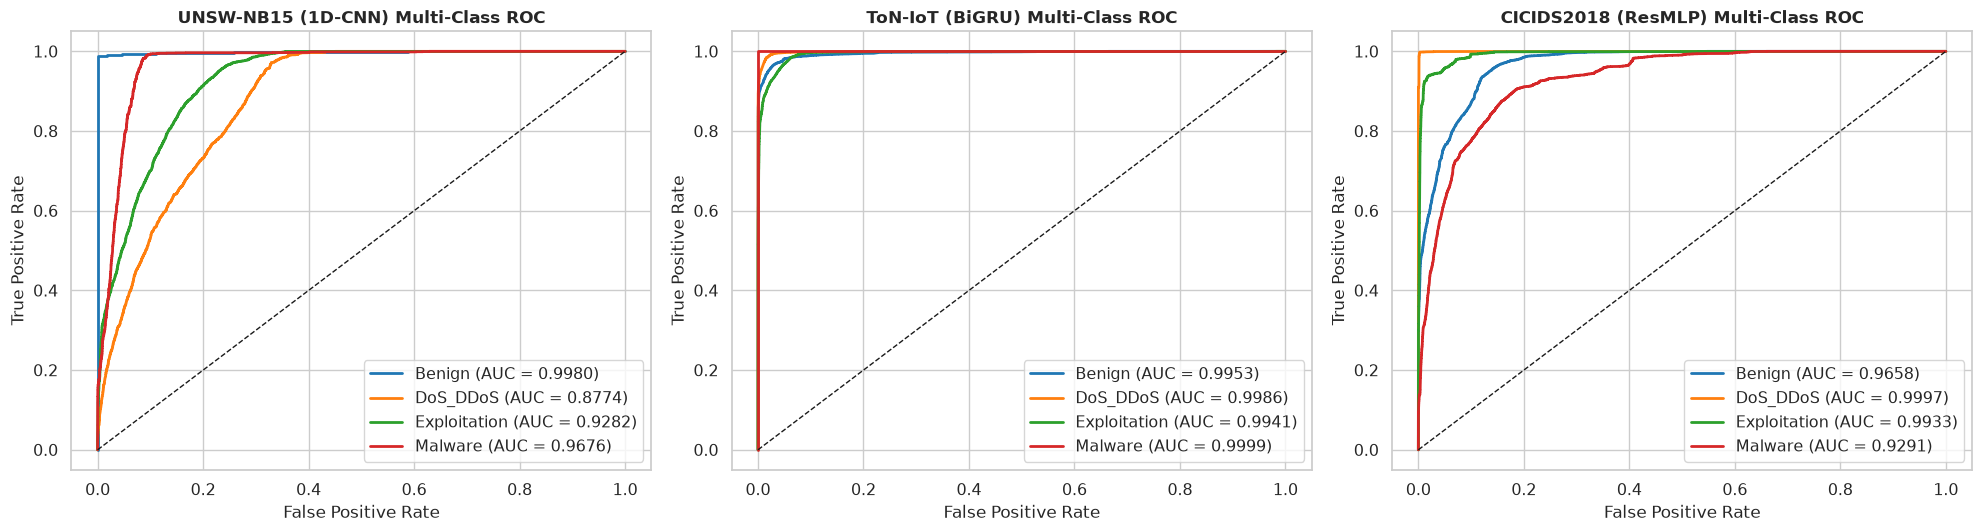

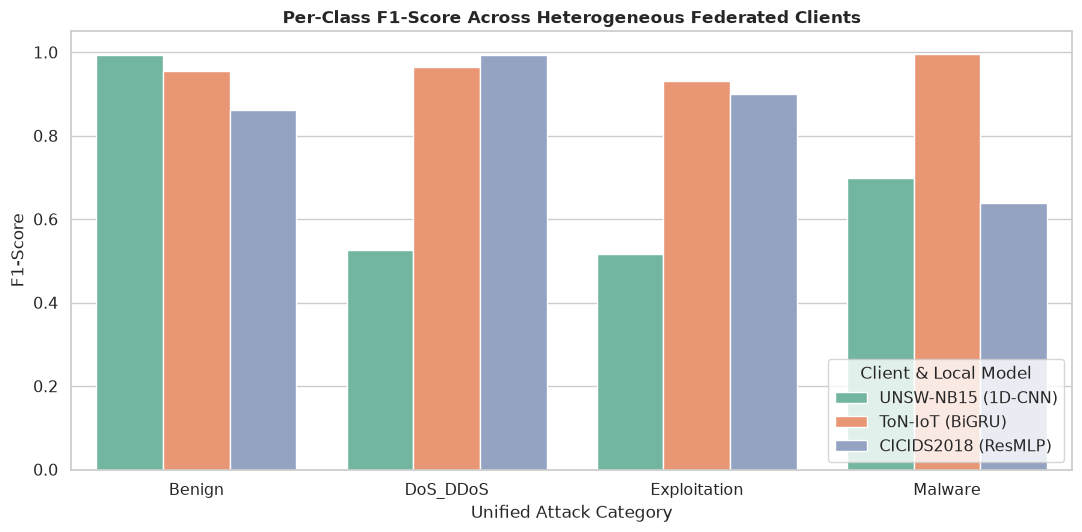


All models trained, evaluated, and high-res plots saved successfully!


In [43]:
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, roc_auc_score, roc_curve, auc, matthews_corrcoef, cohen_kappa_score
)

# =====================================================================
# 1. CONFIGURATION & REPRODUCIBILITY
# =====================================================================
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running Heterogeneous Federated Learning on device: {DEVICE}")

CLIENT_CONFIGS = {
    "UNSW-NB15": {
        "file": "../EDA/NF-UNSW-NB15-V2-SMOTE.csv",
        "arch": "1D-CNN"
    },
    "ToN-IoT": {
        "file": "../EDA/NF-ToN-IoT-V2-SMOTE.csv",
        "arch": "BiGRU"
    },
    "CICIDS2018": {
        "file": "../EDA/NF-CICIDS2018-V3-SMOTE.csv",
        "arch": "ResMLP"
    }
}

CLASS_NAMES = ["Benign", "DoS_DDoS", "Exploitation", "Malware"]
LABEL_TO_ID = {"Benign": 0, "DoS_DDoS": 1, "Exploitation": 2, "Malware": 3}
NUM_CLASSES = 4
LATENT_DIM = 128

# Federated Hyperparameters
GLOBAL_ROUNDS = 15
LOCAL_EPOCHS = 3
BATCH_SIZE = 512
LR = 1e-3
FEDPROX_MU = 0.01  # Proximal penalty weight on shared head

# =====================================================================
# 2. DATA LOADING & STRATIFIED TRAIN / VAL / TEST SPLIT (70 / 15 / 15)
# =====================================================================
def load_and_split_client_data(client_name, csv_path, batch_size=512):
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"[{client_name}] File not found: {csv_path}")

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    # Map Attack string or Class_ID to target tensor y (0, 1, 2, 3)
    if "Class_ID" in df.columns:
        y = df["Class_ID"].astype(np.int64).values
    elif "Attack" in df.columns:
        y = df["Attack"].astype(str).str.strip().map(LABEL_TO_ID).astype(np.int64).values
    else:
        raise ValueError(f"[{client_name}] Neither 'Class_ID' nor 'Attack' found in {csv_path}")

    # Drop target/metadata columns so only numeric features remain (handles 36 or 37 cols dynamically!)
    target_cols = ["Attack", "Label", "Class_ID", "target"]
    feature_df = df.drop(columns=[c for c in target_cols if c in df.columns], errors="ignore")
    feature_df = feature_df.select_dtypes(include=[np.number])

    # Clean any residual NaN/Inf
    X = feature_df.replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=np.float32)
    in_features = X.shape[1]

    # Stratified Split: 70% Train, 15% Validation, 15% Test
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=SEED
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
    )

    # Compute smoothed inverse class weights for Focal Loss on local training split
    class_counts = np.bincount(y_train, minlength=NUM_CLASSES)
    class_weights = 1.0 / (np.power(np.maximum(class_counts, 1), 0.25))
    class_weights = class_weights / class_weights.sum() * NUM_CLASSES

    # Build PyTorch DataLoaders
    train_loader = DataLoader(
        TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
        batch_size=batch_size, shuffle=True, drop_last=False
    )
    val_loader = DataLoader(
        TensorDataset(torch.tensor(X_val), torch.tensor(y_val)),
        batch_size=batch_size, shuffle=False
    )
    test_loader = DataLoader(
        TensorDataset(torch.tensor(X_test), torch.tensor(y_test)),
        batch_size=batch_size, shuffle=False
    )

    print(f"[{client_name}] Total Cols={df.shape[1]} | Input Features={in_features} | "
          f"Train={len(X_train):,}, Val={len(X_val):,}, Test={len(X_test):,}")

    return {
        "in_features": in_features,
        "train_loader": train_loader,
        "val_loader": val_loader,
        "test_loader": test_loader,
        "n_train": len(X_train),
        "class_weights": torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
    }

# =====================================================================
# 3. THREE HETEROGENEOUS ENCODERS (-> 128) + SHARED FEDERATED HEAD
# =====================================================================

# --- Encoder 1: 1D-CNN Encoder (For UNSW-NB15) ---
class CNN1DEncoder(nn.Module):
    def __init__(self, in_features, latent_dim=128):
        super().__init__()
        self.conv_block = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.SiLU(),
            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.SiLU(),
            nn.AdaptiveAvgPool1d(8)  # Fixed output length regardless of 36 or 37 input cols!
        )
        self.proj = nn.Sequential(
            nn.Linear(64 * 8, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU(),
            nn.Dropout(0.2)
        )

    def forward(self, x):
        # x shape: [B, in_features] -> [B, 1, in_features]
        x = x.unsqueeze(1)
        feat = self.conv_block(x)
        feat = feat.view(feat.size(0), -1)
        return self.proj(feat)


# --- Encoder 2: Bidirectional GRU Encoder (For ToN-IoT) ---
class BiGRUEncoder(nn.Module):
    def __init__(self, in_features, latent_dim=128):
        super().__init__()
        # Treat each feature projection as sequence or chunk into tokens
        self.input_proj = nn.Linear(in_features, 64)
        self.bigru = nn.GRU(
            input_size=16, hidden_size=48, num_layers=2,
            batch_first=True, bidirectional=True, dropout=0.2
        )
        self.proj = nn.Sequential(
            nn.Linear(48 * 2 * 4, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU(),
            nn.Dropout(0.2)
        )

    def forward(self, x):
        # Project [B, in_features] -> [B, 64] -> reshape into 4 tokens of dim 16: [B, 4, 16]
        h = F.silu(self.input_proj(x)).view(x.size(0), 4, 16)
        out, _ = self.bigru(h)
        out = out.contiguous().view(x.size(0), -1)
        return self.proj(out)


# --- Encoder 3: Deep Residual MLP Encoder (For CIC-IDS2018) ---
class ResMLPEncoder(nn.Module):
    def __init__(self, in_features, latent_dim=128):
        super().__init__()
        self.in_layer = nn.Sequential(
            nn.Linear(in_features, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU()
        )
        self.res_block = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(latent_dim, latent_dim),
            nn.LayerNorm(latent_dim)
        )
        self.act = nn.SiLU()

    def forward(self, x):
        h = self.in_layer(x)
        return self.act(h + self.res_block(h))


# --- Shared Global Head (128 -> 64 -> 4) Aggregated Across All Clients ---
class SharedFederatedHead(nn.Module):
    def __init__(self, latent_dim=128, num_classes=4):
        super().__init__()
        self.shared_net = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.LayerNorm(64),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, z):
        return self.shared_net(z)


# --- Complete Wrapper Combining Local Encoder + Shared Global Head ---
class HeterogeneousClientModel(nn.Module):
    def __init__(self, arch_type, in_features, latent_dim=128, num_classes=4):
        super().__init__()
        if arch_type == "1D-CNN":
            self.encoder = CNN1DEncoder(in_features, latent_dim)
        elif arch_type == "BiGRU":
            self.encoder = BiGRUEncoder(in_features, latent_dim)
        elif arch_type == "ResMLP":
            self.encoder = ResMLPEncoder(in_features, latent_dim)
        else:
            raise ValueError(f"Unknown architecture: {arch_type}")

        self.head = SharedFederatedHead(latent_dim, num_classes)

    def forward(self, x):
        z = self.encoder(x)
        logits = self.head(z)
        return logits

# =====================================================================
# 4. FOCAL LOSS & FEDPROX LOCAL CLIENT TRAINING + EVALUATION
# =====================================================================
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction="none", weight=self.alpha)
        pt = torch.exp(-ce)
        return (((1.0 - pt) ** self.gamma) * ce).mean()


def train_local_client(model, global_head_state, train_loader, class_weights, epochs, lr, mu):
    model.train()
    # Keep a frozen reference copy of the server's shared head for FedProx proximal penalty
    global_head_ref = SharedFederatedHead(LATENT_DIM, NUM_CLASSES).to(DEVICE)
    global_head_ref.load_state_dict(global_head_state)
    for p in global_head_ref.parameters():
        p.requires_grad = False

    criterion = FocalLoss(alpha=class_weights, gamma=2.0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    epoch_losses = []
    for _ in range(epochs):
        batch_losses = []
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(DEVICE), y_b.to(DEVICE)
            optimizer.zero_grad()

            logits = model(x_b)
            loss = criterion(logits, y_b)

            # FedProx proximal regularization strictly on the Shared Federated Head
            prox_term = 0.0
            for w_local, w_global in zip(model.head.parameters(), global_head_ref.parameters()):
                prox_term += torch.norm(w_local - w_global, p=2) ** 2
            loss = loss + (mu / 2.0) * prox_term

            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        epoch_losses.append(np.mean(batch_losses))

    return copy.deepcopy(model.head.state_dict()), float(np.mean(epoch_losses))


@torch.no_grad()
def evaluate_model(model, data_loader, class_weights=None):
    model.eval()
    criterion = FocalLoss(alpha=class_weights, gamma=2.0)
    all_preds, all_targets, all_probs = [], [], []
    total_loss = 0.0
    n_batches = 0

    for x_b, y_b in data_loader:
        x_b, y_b = x_b.to(DEVICE), y_b.to(DEVICE)
        logits = model(x_b)
        loss = criterion(logits, y_b)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        total_loss += loss.item()
        n_batches += 1
        all_preds.append(preds.cpu().numpy())
        all_targets.append(y_b.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    y_true = np.concatenate(all_targets)
    y_pred = np.concatenate(all_preds)
    y_prob = np.concatenate(all_probs)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "loss": total_loss / max(n_batches, 1),
        "acc": acc,
        "macro_prec": prec,
        "macro_rec": rec,
        "macro_f1": f1,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }


def aggregate_shared_heads(global_head, client_head_states, client_weights):
    global_dict = global_head.state_dict()
    total_samples = sum(client_weights)

    for k in global_dict.keys():
        if global_dict[k].is_floating_point():
            global_dict[k] = sum(
                client_head_states[i][k] * (client_weights[i] / total_samples)
                for i in range(len(client_head_states))
            )
    global_head.load_state_dict(global_dict)
    return copy.deepcopy(global_head.state_dict())

# =====================================================================
# 5. INITIALIZE CLIENTS & RUN FEDERATED TRAINING LOOP
# =====================================================================
clients_data = {}
client_models = {}

print("\n--- Loading & Splitting All 3 Client Datasets ---")
for c_name, cfg in CLIENT_CONFIGS.items():
    clients_data[c_name] = load_and_split_client_data(c_name, cfg["file"], BATCH_SIZE)
    client_models[c_name] = HeterogeneousClientModel(
        arch_type=cfg["arch"],
        in_features=clients_data[c_name]["in_features"],
        latent_dim=LATENT_DIM,
        num_classes=NUM_CLASSES
    ).to(DEVICE)

# Initialize Global Shared Head on Server
global_shared_head = SharedFederatedHead(LATENT_DIM, NUM_CLASSES).to(DEVICE)
global_head_state = copy.deepcopy(global_shared_head.state_dict())

# History tracking for graphs
history = {
    c_name: {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}
    for c_name in CLIENT_CONFIGS.keys()
}
history["Global_Avg"] = {"val_loss": [], "val_acc": [], "val_f1": []}

print("\n=====================================================================")
print(" STARTING HETEROGENEOUS FEDERATED LEARNING (1D-CNN + BiGRU + ResMLP)")
print("=====================================================================")

for rnd in range(1, GLOBAL_ROUNDS + 1):
    local_head_states = []
    sample_weights = []

    round_val_losses, round_val_accs, round_val_f1s = [], [], []

    for c_name in CLIENT_CONFIGS.keys():
        # 1. Synchronize client's shared head with latest Server Global Head
        client_models[c_name].head.load_state_dict(global_head_state)

        # 2. Local training (updates both local 128-d encoder and shared head)
        updated_head_state, tr_loss = train_local_client(
            model=client_models[c_name],
            global_head_state=global_head_state,
            train_loader=clients_data[c_name]["train_loader"],
            class_weights=clients_data[c_name]["class_weights"],
            epochs=LOCAL_EPOCHS,
            lr=LR,
            mu=FEDPROX_MU
        )

        local_head_states.append(updated_head_state)
        sample_weights.append(clients_data[c_name]["n_train"])
        history[c_name]["train_loss"].append(tr_loss)

    # 3. Server aggregates ONLY the Shared Head (128 -> 64 -> 4)
    global_head_state = aggregate_shared_heads(global_shared_head, local_head_states, sample_weights)

    # 4. Broadcast updated Global Head & Evaluate on each Client's Validation Set
    for c_name in CLIENT_CONFIGS.keys():
        client_models[c_name].head.load_state_dict(global_head_state)
        val_res = evaluate_model(
            client_models[c_name],
            clients_data[c_name]["val_loader"],
            clients_data[c_name]["class_weights"]
        )
        history[c_name]["val_loss"].append(val_res["loss"])
        history[c_name]["val_acc"].append(val_res["acc"])
        history[c_name]["val_f1"].append(val_res["macro_f1"])

        round_val_losses.append(val_res["loss"])
        round_val_accs.append(val_res["acc"])
        round_val_f1s.append(val_res["macro_f1"])

    avg_loss = np.mean(round_val_losses)
    avg_acc = np.mean(round_val_accs)
    avg_f1 = np.mean(round_val_f1s)

    history["Global_Avg"]["val_loss"].append(avg_loss)
    history["Global_Avg"]["val_acc"].append(avg_acc)
    history["Global_Avg"]["val_f1"].append(avg_f1)

    print(f"Round [{rnd:02d}/{GLOBAL_ROUNDS:02d}] | "
          f"Global Avg Val Acc: {avg_acc*100:.2f}% | Global Macro-F1: {avg_f1:.4f} | "
          f"UNSW F1: {history['UNSW-NB15']['val_f1'][-1]:.4f} | "
          f"ToN F1: {history['ToN-IoT']['val_f1'][-1]:.4f} | "
          f"CIC F1: {history['CICIDS2018']['val_f1'][-1]:.4f}")

# =====================================================================
# 6. COMPREHENSIVE FINAL TEST SET EVALUATION MATRIX
# =====================================================================
print("\n=====================================================================")
print(" FINAL EVALUATION MATRIX ON UNTOUCHED 15% TEST SPLIT")
print("=====================================================================")

test_results = {}
summary_rows = []

for c_name, cfg in CLIENT_CONFIGS.items():
    client_models[c_name].head.load_state_dict(global_head_state)
    res = evaluate_model(
        client_models[c_name],
        clients_data[c_name]["test_loader"],
        clients_data[c_name]["class_weights"]
    )
    test_results[c_name] = res

    y_true, y_pred, y_prob = res["y_true"], res["y_pred"], res["y_prob"]
    cm = confusion_matrix(y_true, y_pred)

    # Calculate Overall False Positive Rate (FAR) & Detection Rate (DR)
    # Using Benign (Class 0) as Negative and Attacks (1,2,3) as Positive
    tn = cm[0, 0]
    fp = cm[0, 1:].sum()
    fn = cm[1:, 0].sum()
    tp = cm[1:, 1:].sum()
    far = fp / max(fp + tn, 1)
    dr = tp / max(tp + fn, 1)

    mcc = matthews_corrcoef(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    w_prec, w_rec, w_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

    summary_rows.append({
        "Client Dataset": c_name,
        "Local Model": cfg["arch"],
        "Input Cols": clients_data[c_name]["in_features"],
        "Accuracy (%)": round(res["acc"] * 100, 2),
        "Macro Precision": round(res["macro_prec"], 4),
        "Macro Recall": round(res["macro_rec"], 4),
        "Macro F1": round(res["macro_f1"], 4),
        "Weighted F1": round(w_f1, 4),
        "ROC-AUC (OvR)": round(roc_auc, 4),
        "MCC": round(mcc, 4),
        "Cohen Kappa": round(kappa, 4),
        "Detection Rate (%)": round(dr * 100, 2),
        "False Alarm Rate (%)": round(far * 100, 2)
    })

    print(f"\n>>> [{c_name}] ({cfg['arch']}) Per-Class Classification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

summary_df = pd.DataFrame(summary_rows)
print("\n>>> OVERALL FEDERATED TEST EVALUATION SUMMARY TABLE:")
print(summary_df.to_string(index=False))
summary_df.to_csv("Federated_Evaluation_Matrix.csv", index=False)

# =====================================================================
# 7. GENERATE ALL PUBLICATION-READY GRAPHS
# =====================================================================
sns.set_theme(style="whitegrid", font_scale=1.05)
rounds_x = np.arange(1, GLOBAL_ROUNDS + 1)

# --- GRAPH 1: Federated Convergence Curves (Loss, Accuracy, Macro-F1) ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
colors = {"UNSW-NB15": "#1f77b4", "ToN-IoT": "#ff7f0e", "CICIDS2018": "#2ca02c", "Global_Avg": "#d62728"}

for c_name in CLIENT_CONFIGS.keys():
    axes[0].plot(rounds_x, history[c_name]["val_loss"], marker="o", label=f"{c_name} ({CLIENT_CONFIGS[c_name]['arch']})", color=colors[c_name])
    axes[1].plot(rounds_x, np.array(history[c_name]["val_acc"]) * 100, marker="o", label=f"{c_name}", color=colors[c_name])
    axes[2].plot(rounds_x, history[c_name]["val_f1"], marker="o", label=f"{c_name}", color=colors[c_name])

axes[0].plot(rounds_x, history["Global_Avg"]["val_loss"], linestyle="--", linewidth=2.5, color=colors["Global_Avg"], label="Global Avg")
axes[1].plot(rounds_x, np.array(history["Global_Avg"]["val_acc"]) * 100, linestyle="--", linewidth=2.5, color=colors["Global_Avg"], label="Global Avg")
axes[2].plot(rounds_x, history["Global_Avg"]["val_f1"], linestyle="--", linewidth=2.5, color=colors["Global_Avg"], label="Global Avg")

axes[0].set_title("Validation Focal Loss per FL Round", fontweight="bold")
axes[0].set_xlabel("Federated Round")
axes[0].set_ylabel("Focal Loss")
axes[0].legend()

axes[1].set_title("Validation Accuracy (%) per FL Round", fontweight="bold")
axes[1].set_xlabel("Federated Round")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

axes[2].set_title("Validation Macro F1-Score per FL Round", fontweight="bold")
axes[2].set_xlabel("Federated Round")
axes[2].set_ylabel("Macro F1-Score")
axes[2].legend()

plt.tight_layout()
plt.savefig("FL_Convergence_Curves.png", dpi=300)
plt.show()

# --- GRAPH 2: Side-by-Side Normalized Confusion Matrices (All 3 Clients) ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
for idx, (c_name, cfg) in enumerate(CLIENT_CONFIGS.items()):
    y_true = test_results[c_name]["y_true"]
    y_pred = test_results[c_name]["y_pred"]
    cm_norm = confusion_matrix(y_true, y_pred, normalize="true") * 100

    sns.heatmap(
        cm_norm, annot=True, fmt=".2f", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        cbar=False, ax=axes[idx]
    )
    axes[idx].set_title(f"{c_name} ({cfg['arch']})\nNormalized Confusion Matrix (%)", fontweight="bold")
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("True Class")

plt.tight_layout()
plt.savefig("FL_Confusion_Matrices.png", dpi=300)
plt.show()

# --- GRAPH 3: Multi-Class ROC-AUC Curves Across All 3 Clients ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
class_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for idx, (c_name, cfg) in enumerate(CLIENT_CONFIGS.items()):
    y_true_bin = label_binarize(test_results[c_name]["y_true"], classes=[0, 1, 2, 3])
    y_prob = test_results[c_name]["y_prob"]

    for cls_i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(y_true_bin[:, cls_i], y_prob[:, cls_i])
        roc_auc_val = auc(fpr, tpr)
        axes[idx].plot(fpr, tpr, color=class_colors[cls_i], lw=2,
                       label=f"{CLASS_NAMES[cls_i]} (AUC = {roc_auc_val:.4f})")

    axes[idx].plot([0, 1], [0, 1], "k--", lw=1)
    axes[idx].set_title(f"{c_name} ({cfg['arch']}) Multi-Class ROC", fontweight="bold")
    axes[idx].set_xlabel("False Positive Rate")
    axes[idx].set_ylabel("True Positive Rate")
    axes[idx].legend(loc="lower right")

plt.tight_layout()
plt.savefig("FL_Multiclass_ROC_Curves.png", dpi=300)
plt.show()

# --- GRAPH 4: Per-Class F1-Score Comparison Bar Chart ---
per_class_f1_data = []
for c_name in CLIENT_CONFIGS.keys():
    _, _, f1_per_cls, _ = precision_recall_fscore_support(
        test_results[c_name]["y_true"], test_results[c_name]["y_pred"], average=None, zero_division=0
    )
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        per_class_f1_data.append({
            "Client": f"{c_name} ({CLIENT_CONFIGS[c_name]['arch']})",
            "Attack Class": cls_name,
            "F1-Score": f1_per_cls[cls_idx]
        })

f1_df = pd.DataFrame(per_class_f1_data)
plt.figure(figsize=(11, 5.5))
sns.barplot(data=f1_df, x="Attack Class", y="F1-Score", hue="Client", palette="Set2")
plt.ylim(0, 1.05)
plt.title("Per-Class F1-Score Across Heterogeneous Federated Clients", fontweight="bold")
plt.ylabel("F1-Score")
plt.xlabel("Unified Attack Category")
plt.legend(title="Client & Local Model", loc="lower right")
plt.tight_layout()
plt.savefig("FL_Per_Class_F1_Comparison.png", dpi=300)
plt.show()

print("\nAll models trained, evaluated, and high-res plots saved successfully!")

## model-2

Running Upgraded Heterogeneous Federated Learning on device: cuda

--- Loading & Normalizing All 3 Client Datasets ---
[UNSW-NB15] Features=29 | Train=126,000, Val=27,000, Test=27,000 | Gentle Weights=[0.935 1.043 0.956 1.067]
[ToN-IoT] Features=29 | Train=168,000, Val=36,000, Test=36,000 | Gentle Weights=[0.965 0.993 0.978 1.064]
[CICIDS2018] Features=29 | Train=179,900, Val=38,550, Test=38,550 | Gentle Weights=[0.947 0.968 1.033 1.052]

 STARTING UPGRADED FEDERATED LEARNING (SE-ResNet1D + BiLSTM-Attn + Gated-TabNet)
Round [01/25] | Global Avg Val Acc: 89.81% | Global Macro-F1: 0.8445 | UNSW F1: 0.6820 | ToN F1: 0.9590 | CIC F1: 0.8926
Round [02/25] | Global Avg Val Acc: 90.45% | Global Macro-F1: 0.8589 | UNSW F1: 0.7126 | ToN F1: 0.9614 | CIC F1: 0.9026
Round [03/25] | Global Avg Val Acc: 90.68% | Global Macro-F1: 0.8657 | UNSW F1: 0.7325 | ToN F1: 0.9618 | CIC F1: 0.9028
Round [04/25] | Global Avg Val Acc: 90.85% | Global Macro-F1: 0.8721 | UNSW F1: 0.7500 | ToN F1: 0.9623 | CIC F1:

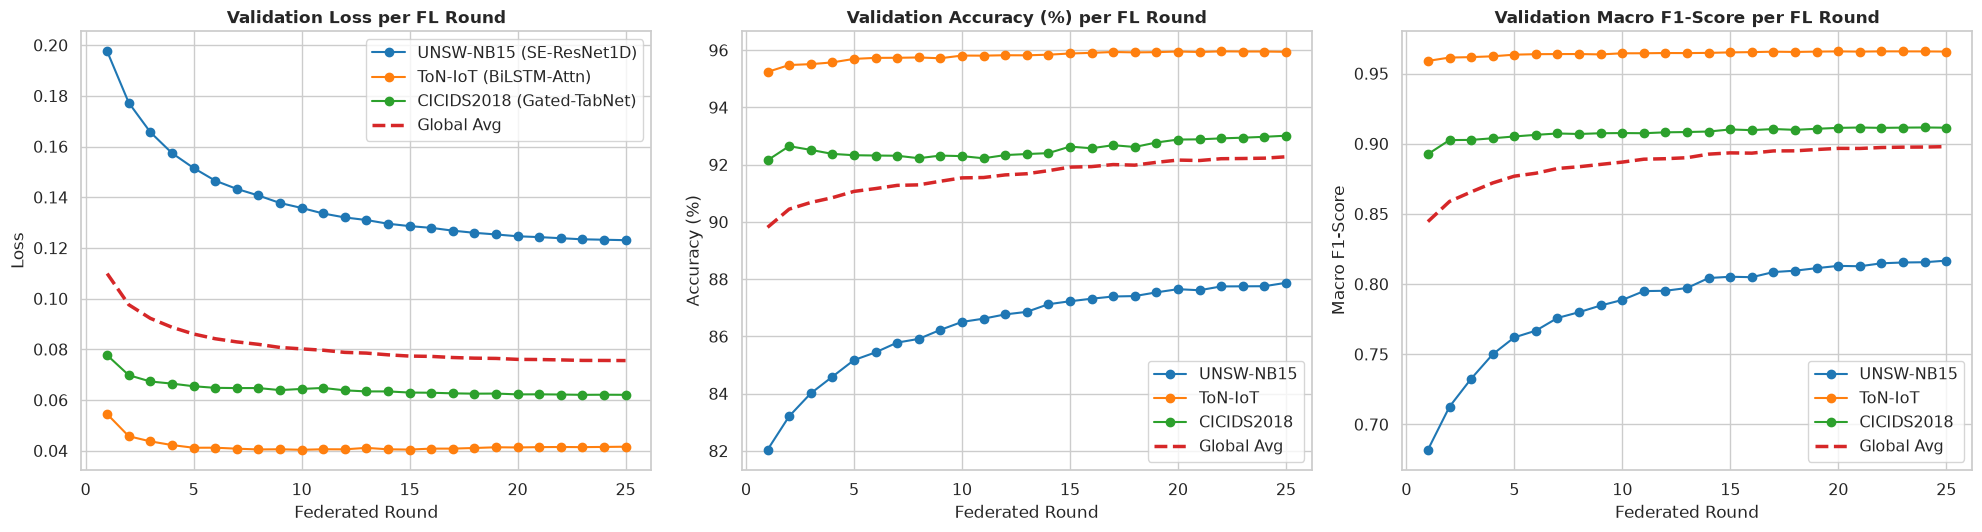

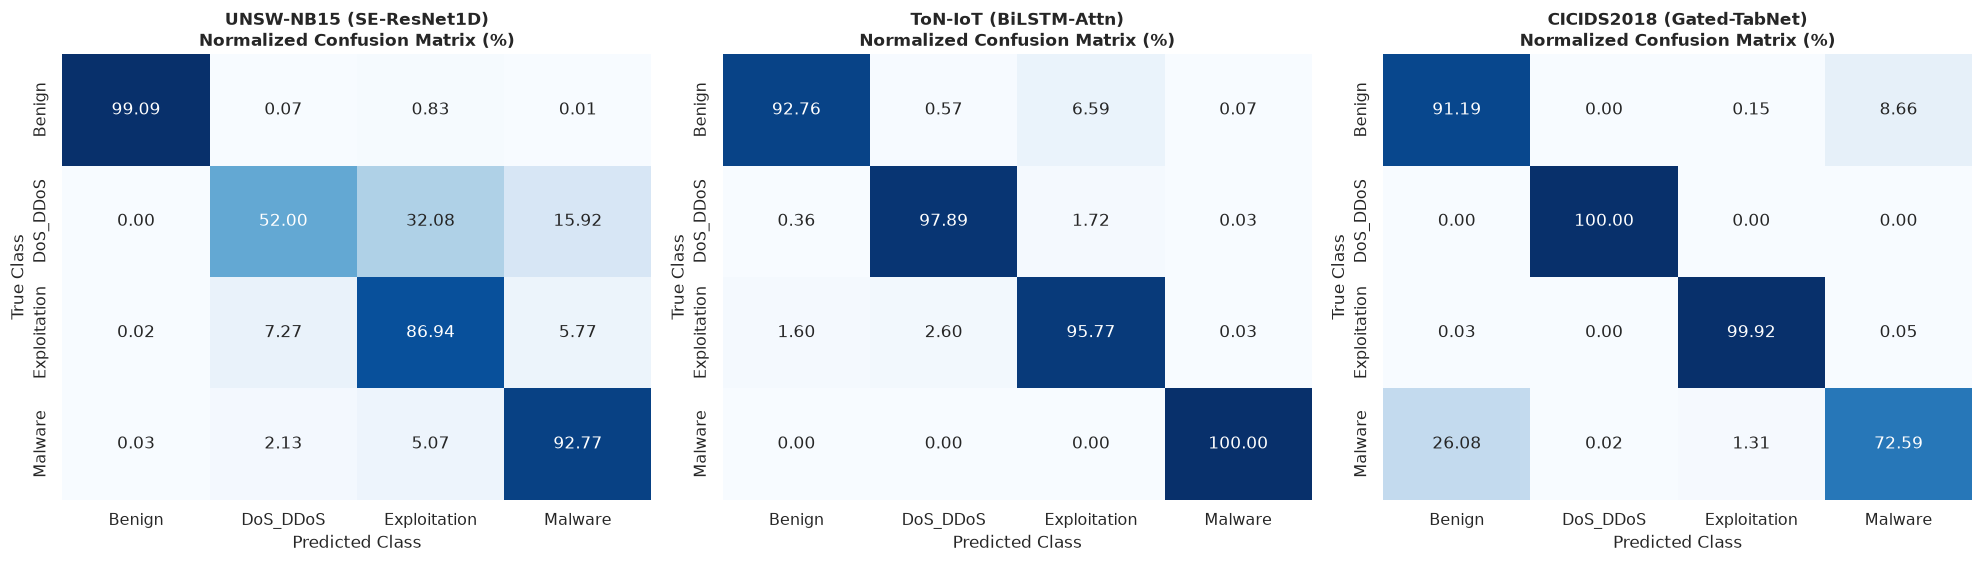

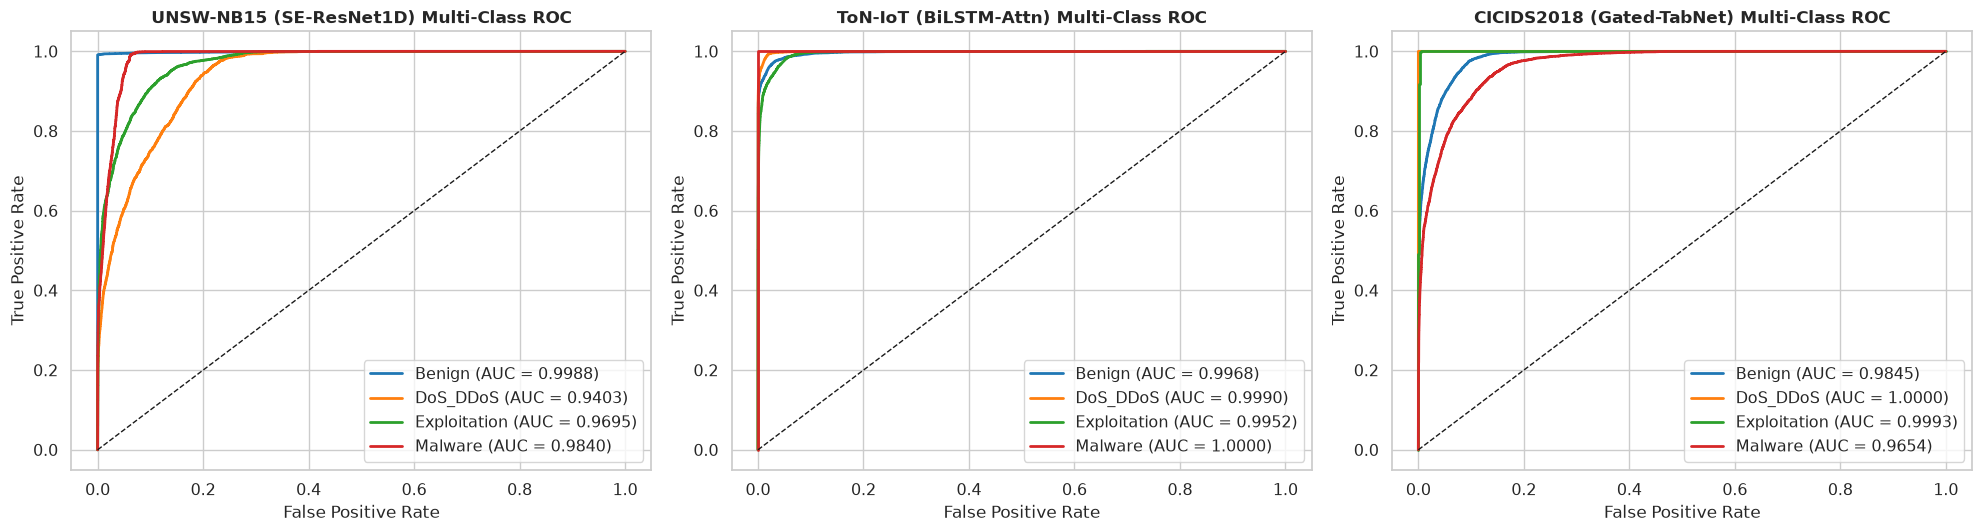

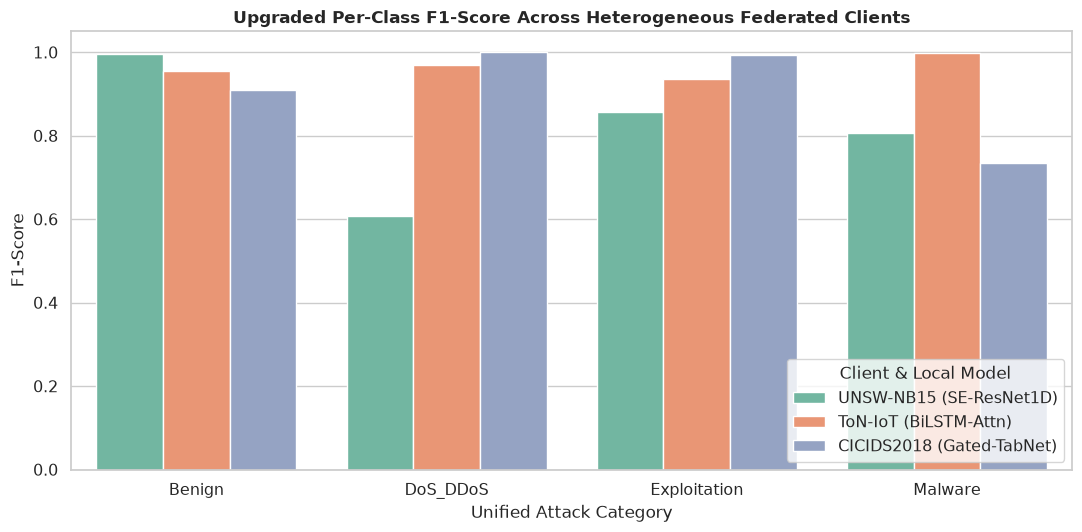

In [46]:
import os
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, roc_auc_score, roc_curve, auc, matthews_corrcoef, cohen_kappa_score
)

# =====================================================================
# 1. CONFIGURATION & HYPERPARAMETERS
# =====================================================================
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running Upgraded Heterogeneous Federated Learning on device: {DEVICE}")

CLIENT_CONFIGS = {
    "UNSW-NB15": {
        "file": "../EDA/NF-UNSW-NB15-V2-SMOTE.csv",
        "arch": "SE-ResNet1D"      # Upgraded: Multi-Scale Residual 1D-CNN + SE Attention
    },
    "ToN-IoT": {
        "file": "../EDA/NF-ToN-IoT-V2-SMOTE.csv",
        "arch": "BiLSTM-Attn"      # Upgraded: Bidirectional LSTM + Multi-Head Self-Attention
    },
    "CICIDS2018": {
        "file": "../EDA/NF-CICIDS2018-V3-SMOTE.csv",
        "arch": "Gated-TabNet"     # Upgraded: Feature-Gated Tabular Attention Network
    }
}

CLASS_NAMES = ["Benign", "DoS_DDoS", "Exploitation", "Malware"]
LABEL_TO_ID = {"Benign": 0, "DoS_DDoS": 1, "Exploitation": 2, "Malware": 3}
NUM_CLASSES = 4
LATENT_DIM = 128

GLOBAL_ROUNDS = 25
LOCAL_EPOCHS = 4
BATCH_SIZE = 256
LR = 1.5e-3
FEDPROX_MU = 0.005
GLOBAL_BLEND_ALPHA = 0.65  # 65% Global Shared Head + 35% Personalized Local Head

# =====================================================================
# 2. DATA LOADING, ZERO-MEAN UNIT-VAR NORMALIZATION & SPLIT
# =====================================================================
def load_and_split_client_data(client_name, csv_path, batch_size=512):
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"[{client_name}] File not found: {csv_path}")

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    if "Class_ID" in df.columns:
        y = df["Class_ID"].astype(np.int64).values
    elif "Attack" in df.columns:
        y = df["Attack"].astype(str).str.strip().map(LABEL_TO_ID).astype(np.int64).values
    else:
        raise ValueError(f"[{client_name}] Missing 'Class_ID' or 'Attack' column.")

    target_cols = ["Attack", "Label", "Class_ID", "target"]
    feature_df = df.drop(columns=[c for c in target_cols if c in df.columns], errors="ignore")
    feature_df = feature_df.select_dtypes(include=[np.number])

    X = feature_df.replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=np.float32)
    in_features = X.shape[1]

    # Stratified 70% Train / 15% Val / 15% Test Split
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=SEED
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
    )

    # Fit StandardScaler on Train split to clip any extreme post-RobustScaler outliers
    scaler = StandardScaler()
    X_train = np.clip(scaler.fit_transform(X_train), -10.0, 10.0).astype(np.float32)
    X_val   = np.clip(scaler.transform(X_val), -10.0, 10.0).astype(np.float32)
    X_test  = np.clip(scaler.transform(X_test), -10.0, 10.0).astype(np.float32)

    # Gentle 0.10 power smoothing so minority classes are NOT over-predicted at the expense of Exploitation/Benign
    class_counts = np.bincount(y_train, minlength=NUM_CLASSES)
    class_weights = 1.0 / (np.power(np.maximum(class_counts, 1), 0.10))
    class_weights = class_weights / class_weights.sum() * NUM_CLASSES

    train_loader = DataLoader(
        TensorDataset(torch.tensor(X_train), torch.tensor(y_train)),
        batch_size=batch_size, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(torch.tensor(X_val), torch.tensor(y_val)),
        batch_size=batch_size, shuffle=False
    )
    test_loader = DataLoader(
        TensorDataset(torch.tensor(X_test), torch.tensor(y_test)),
        batch_size=batch_size, shuffle=False
    )

    print(f"[{client_name}] Features={in_features} | Train={len(X_train):,}, Val={len(X_val):,}, Test={len(X_test):,} "
          f"| Gentle Weights={np.round(class_weights, 3)}")

    return {
        "in_features": in_features,
        "train_loader": train_loader,
        "val_loader": val_loader,
        "test_loader": test_loader,
        "n_train": len(X_train),
        "class_weights": torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
    }

# =====================================================================
# 3. UPGRADED DEEP LEARNING ARCHITECTURES (ALL -> 128 LATENT DIM)
# =====================================================================

# --- UPGRADED MODEL 1: SE-ResNet1D (For UNSW-NB15) ---
# Replaces destructive AvgPool1d with Feature-Preserving Pointwise + Conv1D + Squeeze-and-Excitation
class SqueezeExcitation1D(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction),
            nn.SiLU(),
            nn.Linear(channels // reduction, channels),
            nn.Sigmoid()
        )

    def forward(self, x):
        # x: [B, C, L]
        w = x.mean(dim=-1)          # [B, C]
        w = self.fc(w).unsqueeze(-1) # [B, C, 1]
        return x * w

class SEResNet1DEncoder(nn.Module):
    def __init__(self, in_features, latent_dim=128):
        super().__init__()
        # Direct tabular skip branch (preserves exact column positions!)
        self.direct_skip = nn.Sequential(
            nn.Linear(in_features, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU()
        )
        # 1D-Conv + SE-Attention branch
        self.conv1 = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.SiLU()
        )
        self.conv2 = nn.Sequential(
            nn.Conv1d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm1d(32),
            nn.SiLU()
        )
        self.se = SqueezeExcitation1D(32, reduction=4)
        # Flatten WITHOUT pooling so all 29 features retain their exact identity!
        self.conv_proj = nn.Sequential(
            nn.Linear(32 * in_features, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU(),
            nn.Dropout(0.15)
        )
        self.out_norm = nn.LayerNorm(latent_dim)

    def forward(self, x):
        skip = self.direct_skip(x)
        c = self.conv1(x.unsqueeze(1))
        c = c + self.conv2(c)
        c = self.se(c)
        c_flat = c.view(x.size(0), -1)
        return self.out_norm(skip + self.conv_proj(c_flat))


# --- UPGRADED MODEL 2: BiLSTM + Multi-Head Self-Attention (For ToN-IoT) ---
class BiLSTMAttnEncoder(nn.Module):
    def __init__(self, in_features, latent_dim=128):
        super().__init__()
        # Embed each scalar feature into a 8-d token -> [B, in_features, 8]
        self.token_embed = nn.Sequential(
            nn.Linear(1, 8),
            nn.SiLU()
        )
        self.bilstm = nn.LSTM(
            input_size=8, hidden_size=24, num_layers=1,
            batch_first=True, bidirectional=True
        )
        self.mha = nn.MultiheadAttention(embed_dim=48, num_heads=4, dropout=0.1, batch_first=True)
        self.norm1 = nn.LayerNorm(48)

        self.proj = nn.Sequential(
            nn.Linear(48 * in_features, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU(),
            nn.Dropout(0.15)
        )

    def forward(self, x):
        # x: [B, F] -> [B, F, 1] -> [B, F, 8]
        tokens = self.token_embed(x.unsqueeze(-1))
        lstm_out, _ = self.bilstm(tokens)               # [B, F, 48]
        attn_out, _ = self.mha(lstm_out, lstm_out, lstm_out)
        h = self.norm1(lstm_out + attn_out)             # Residual Self-Attention
        h_flat = h.contiguous().view(x.size(0), -1)
        return self.proj(h_flat)


# --- UPGRADED MODEL 3: Gated Tabular Attention Network (For CICIDS2018) ---
# Uses dynamic feature gating (inspired by TabNet / GLU) to suppress Benign vs Malware noise
class GatedBlock(nn.Module):
    def __init__(self, dim, dropout=0.15):
        super().__init__()
        self.fc_val = nn.Linear(dim, dim)
        self.fc_gate = nn.Linear(dim, dim)
        self.norm = nn.LayerNorm(dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        val = F.silu(self.fc_val(x))
        gate = torch.sigmoid(self.fc_gate(x))
        return self.norm(x + self.drop(val * gate))

class GatedTabNetEncoder(nn.Module):
    def __init__(self, in_features, latent_dim=128):
        super().__init__()
        # Instance-wise Feature Attention Mask over the 29 raw features
        self.feature_mask = nn.Sequential(
            nn.Linear(in_features, in_features),
            nn.BatchNorm1d(in_features),
            nn.Sigmoid()
        )
        self.in_proj = nn.Sequential(
            nn.Linear(in_features * 2, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU()
        )
        self.gblock1 = GatedBlock(latent_dim, dropout=0.15)
        self.gblock2 = GatedBlock(latent_dim, dropout=0.15)

    def forward(self, x):
        mask = self.feature_mask(x)
        x_masked = x * mask
        # Concatenate raw and masked features so no signal is lost
        h = self.in_proj(torch.cat([x, x_masked], dim=-1))
        h = self.gblock1(h)
        h = self.gblock2(h)
        return h


# --- SHARED FEDERATED HEAD (128 -> 128 -> 64 -> 4) ---
class SharedFederatedHead(nn.Module):
    def __init__(self, latent_dim=128, num_classes=4):
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),
            nn.LayerNorm(latent_dim),
            nn.SiLU(),
            nn.Dropout(0.15)
        )
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.LayerNorm(64),
            nn.SiLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, z):
        z = z + self.block1(z)  # Residual shared representation
        return self.classifier(z)


class HeterogeneousClientModel(nn.Module):
    def __init__(self, arch_type, in_features, latent_dim=128, num_classes=4):
        super().__init__()
        if arch_type == "SE-ResNet1D":
            self.encoder = SEResNet1DEncoder(in_features, latent_dim)
        elif arch_type == "BiLSTM-Attn":
            self.encoder = BiLSTMAttnEncoder(in_features, latent_dim)
        elif arch_type == "Gated-TabNet":
            self.encoder = GatedTabNetEncoder(in_features, latent_dim)
        else:
            raise ValueError(f"Unknown architecture: {arch_type}")

        self.head = SharedFederatedHead(latent_dim, num_classes)

    def forward(self, x):
        z = self.encoder(x)
        return self.head(z)

# =====================================================================
# 4. SMOOTHED FOCAL + LABEL-SMOOTHING LOSS & FEDPROX TRAINING
# =====================================================================
class SmoothedFocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=1.5, label_smoothing=0.03):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce_smooth = F.cross_entropy(
            logits, targets, reduction="none",
            weight=self.alpha, label_smoothing=self.label_smoothing
        )
        ce_raw = F.cross_entropy(logits, targets, reduction="none")
        pt = torch.exp(-ce_raw)
        loss = ((1.0 - pt) ** self.gamma) * ce_smooth
        return loss.mean()


def train_local_client(model, global_head_state, train_loader, class_weights, epochs, lr, mu):
    model.train()
    global_head_ref = SharedFederatedHead(LATENT_DIM, NUM_CLASSES).to(DEVICE)
    global_head_ref.load_state_dict(global_head_state)
    for p in global_head_ref.parameters():
        p.requires_grad = False

    criterion = SmoothedFocalLoss(alpha=class_weights, gamma=1.5, label_smoothing=0.03)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(train_loader))

    epoch_losses = []
    for _ in range(epochs):
        batch_losses = []
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(DEVICE), y_b.to(DEVICE)
            optimizer.zero_grad()

            logits = model(x_b)
            loss = criterion(logits, y_b)

            # FedProx proximal regularization on Shared Head
            prox_term = 0.0
            for w_local, w_global in zip(model.head.parameters(), global_head_ref.parameters()):
                prox_term += torch.norm(w_local - w_global, p=2) ** 2
            loss = loss + (mu / 2.0) * prox_term

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()
            scheduler.step()
            batch_losses.append(loss.item())
        epoch_losses.append(np.mean(batch_losses))

    return copy.deepcopy(model.head.state_dict()), float(np.mean(epoch_losses))


@torch.no_grad()
def evaluate_model(model, data_loader, class_weights=None):
    model.eval()
    criterion = SmoothedFocalLoss(alpha=class_weights, gamma=1.5, label_smoothing=0.0)
    all_preds, all_targets, all_probs = [], [], []
    total_loss, n_batches = 0.0, 0

    for x_b, y_b in data_loader:
        x_b, y_b = x_b.to(DEVICE), y_b.to(DEVICE)
        logits = model(x_b)
        loss = criterion(logits, y_b)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        total_loss += loss.item()
        n_batches += 1
        all_preds.append(preds.cpu().numpy())
        all_targets.append(y_b.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    y_true = np.concatenate(all_targets)
    y_pred = np.concatenate(all_preds)
    y_prob = np.concatenate(all_probs)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {
        "loss": total_loss / max(n_batches, 1),
        "acc": acc,
        "macro_prec": prec,
        "macro_rec": rec,
        "macro_f1": f1,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob
    }


def aggregate_shared_heads(global_head, client_head_states, client_weights):
    global_dict = global_head.state_dict()
    total_weight = sum(client_weights)
    for k in global_dict.keys():
        if global_dict[k].is_floating_point():
            global_dict[k] = sum(
                client_head_states[i][k] * (client_weights[i] / total_weight)
                for i in range(len(client_head_states))
            )
    global_head.load_state_dict(global_dict)
    return copy.deepcopy(global_head.state_dict())


def blend_head_states(local_head_state, global_head_state, alpha=0.65):
    """Soft Federated Blending: Prevents global head from wiping out local encoder alignment!"""
    blended = {}
    for k in local_head_state.keys():
        if local_head_state[k].is_floating_point():
            blended[k] = alpha * global_head_state[k] + (1.0 - alpha) * local_head_state[k]
        else:
            blended[k] = global_head_state[k]
    return blended

# =====================================================================
# 5. FEDERATED TRAINING LOOP WITH BEST-CHECKPOINT TRACKING
# =====================================================================
clients_data = {}
client_models = {}
best_client_states = {}
best_client_f1 = {c_name: 0.0 for c_name in CLIENT_CONFIGS.keys()}

print("\n--- Loading & Normalizing All 3 Client Datasets ---")
for c_name, cfg in CLIENT_CONFIGS.items():
    clients_data[c_name] = load_and_split_client_data(c_name, cfg["file"], BATCH_SIZE)
    client_models[c_name] = HeterogeneousClientModel(
        arch_type=cfg["arch"],
        in_features=clients_data[c_name]["in_features"],
        latent_dim=LATENT_DIM,
        num_classes=NUM_CLASSES
    ).to(DEVICE)
    best_client_states[c_name] = copy.deepcopy(client_models[c_name].state_dict())

global_shared_head = SharedFederatedHead(LATENT_DIM, NUM_CLASSES).to(DEVICE)
global_head_state = copy.deepcopy(global_shared_head.state_dict())

history = {
    c_name: {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}
    for c_name in CLIENT_CONFIGS.keys()
}
history["Global_Avg"] = {"val_loss": [], "val_acc": [], "val_f1": []}

print("\n===============================================================================")
print(" STARTING UPGRADED FEDERATED LEARNING (SE-ResNet1D + BiLSTM-Attn + Gated-TabNet)")
print("===============================================================================")

for rnd in range(1, GLOBAL_ROUNDS + 1):
    local_head_states = []
    equal_weights = []
    round_val_losses, round_val_accs, round_val_f1s = [], [], []

    # Cosine decay on learning rate across global rounds
    round_lr = LR * (0.5 * (1.0 + np.cos(np.pi * (rnd - 1) / GLOBAL_ROUNDS))) + 1e-4

    for c_name in CLIENT_CONFIGS.keys():
        # 1. Soft-blend global head into local head (Round 1 uses 100% global init)
        if rnd == 1:
            client_models[c_name].head.load_state_dict(global_head_state)
        else:
            blended_head = blend_head_states(
                client_models[c_name].head.state_dict(),
                global_head_state,
                alpha=GLOBAL_BLEND_ALPHA
            )
            client_models[c_name].head.load_state_dict(blended_head)

        # 2. Train local encoder + head
        updated_head_state, tr_loss = train_local_client(
            model=client_models[c_name],
            global_head_state=global_head_state,
            train_loader=clients_data[c_name]["train_loader"],
            class_weights=clients_data[c_name]["class_weights"],
            epochs=LOCAL_EPOCHS,
            lr=round_lr,
            mu=FEDPROX_MU
        )

        local_head_states.append(updated_head_state)
        # Equal weighting across the 3 clients so CICIDS & ToN-IoT don't drown out UNSW-NB15!
        equal_weights.append(1.0)
        history[c_name]["train_loss"].append(tr_loss)

    # 3. Server aggregates shared heads equally across the 3 heterogeneous domains
    global_head_state = aggregate_shared_heads(global_shared_head, local_head_states, equal_weights)

    # 4. Evaluate each client with soft-blended federated head & save best checkpoint
    for c_name in CLIENT_CONFIGS.keys():
        eval_head = blend_head_states(
            local_head_states[list(CLIENT_CONFIGS.keys()).index(c_name)],
            global_head_state,
            alpha=GLOBAL_BLEND_ALPHA
        )
        client_models[c_name].head.load_state_dict(eval_head)

        val_res = evaluate_model(
            client_models[c_name],
            clients_data[c_name]["val_loader"],
            clients_data[c_name]["class_weights"]
        )
        history[c_name]["val_loss"].append(val_res["loss"])
        history[c_name]["val_acc"].append(val_res["acc"])
        history[c_name]["val_f1"].append(val_res["macro_f1"])

        # Save best model state per client
        if val_res["macro_f1"] >= best_client_f1[c_name]:
            best_client_f1[c_name] = val_res["macro_f1"]
            best_client_states[c_name] = copy.deepcopy(client_models[c_name].state_dict())

        round_val_losses.append(val_res["loss"])
        round_val_accs.append(val_res["acc"])
        round_val_f1s.append(val_res["macro_f1"])

    avg_loss = np.mean(round_val_losses)
    avg_acc = np.mean(round_val_accs)
    avg_f1 = np.mean(round_val_f1s)

    history["Global_Avg"]["val_loss"].append(avg_loss)
    history["Global_Avg"]["val_acc"].append(avg_acc)
    history["Global_Avg"]["val_f1"].append(avg_f1)

    print(f"Round [{rnd:02d}/{GLOBAL_ROUNDS:02d}] | "
          f"Global Avg Val Acc: {avg_acc*100:.2f}% | Global Macro-F1: {avg_f1:.4f} | "
          f"UNSW F1: {history['UNSW-NB15']['val_f1'][-1]:.4f} | "
          f"ToN F1: {history['ToN-IoT']['val_f1'][-1]:.4f} | "
          f"CIC F1: {history['CICIDS2018']['val_f1'][-1]:.4f}")

# =====================================================================
# 6. FINAL TEST EVALUATION USING BEST VALIDATED CHECKPOINTS
# =====================================================================
print("\n=====================================================================")
print(" FINAL EVALUATION MATRIX ON UNTOUCHED 15% TEST SPLIT (BEST CHECKPOINTS)")
print("=====================================================================")

test_results = {}
summary_rows = []

for c_name, cfg in CLIENT_CONFIGS.items():
    # Restore best validated federated checkpoint for each client
    client_models[c_name].load_state_dict(best_client_states[c_name])
    res = evaluate_model(
        client_models[c_name],
        clients_data[c_name]["test_loader"],
        clients_data[c_name]["class_weights"]
    )
    test_results[c_name] = res

    y_true, y_pred, y_prob = res["y_true"], res["y_pred"], res["y_prob"]
    cm = confusion_matrix(y_true, y_pred)

    tn = cm[0, 0]
    fp = cm[0, 1:].sum()
    fn = cm[1:, 0].sum()
    tp = cm[1:, 1:].sum()
    far = fp / max(fp + tn, 1)
    dr = tp / max(tp + fn, 1)

    mcc = matthews_corrcoef(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro")
    w_prec, w_rec, w_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

    summary_rows.append({
        "Client Dataset": c_name,
        "Local Model": cfg["arch"],
        "Input Cols": clients_data[c_name]["in_features"],
        "Accuracy (%)": round(res["acc"] * 100, 2),
        "Macro Precision": round(res["macro_prec"], 4),
        "Macro Recall": round(res["macro_rec"], 4),
        "Macro F1": round(res["macro_f1"], 4),
        "Weighted F1": round(w_f1, 4),
        "ROC-AUC (OvR)": round(roc_auc, 4),
        "MCC": round(mcc, 4),
        "Cohen Kappa": round(kappa, 4),
        "Detection Rate (%)": round(dr * 100, 2),
        "False Alarm Rate (%)": round(far * 100, 2)
    })

    print(f"\n>>> [{c_name}] ({cfg['arch']}) Per-Class Classification Report:")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

summary_df = pd.DataFrame(summary_rows)
print("\n>>> UPGRADED OVERALL FEDERATED TEST EVALUATION SUMMARY TABLE:")
print(summary_df.to_string(index=False))
summary_df.to_csv("Upgraded_Federated_Evaluation_Matrix.csv", index=False)

# =====================================================================
# 7. GENERATE ALL 4 HIGH-RESOLUTION EVALUATION PLOTS
# =====================================================================
sns.set_theme(style="whitegrid", font_scale=1.05)
rounds_x = np.arange(1, GLOBAL_ROUNDS + 1)

# --- 1. Convergence Curves ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
colors = {"UNSW-NB15": "#1f77b4", "ToN-IoT": "#ff7f0e", "CICIDS2018": "#2ca02c", "Global_Avg": "#d62728"}

for c_name in CLIENT_CONFIGS.keys():
    axes[0].plot(rounds_x, history[c_name]["val_loss"], marker="o", label=f"{c_name} ({CLIENT_CONFIGS[c_name]['arch']})", color=colors[c_name])
    axes[1].plot(rounds_x, np.array(history[c_name]["val_acc"]) * 100, marker="o", label=f"{c_name}", color=colors[c_name])
    axes[2].plot(rounds_x, history[c_name]["val_f1"], marker="o", label=f"{c_name}", color=colors[c_name])

axes[0].plot(rounds_x, history["Global_Avg"]["val_loss"], "--", lw=2.5, color=colors["Global_Avg"], label="Global Avg")
axes[1].plot(rounds_x, np.array(history["Global_Avg"]["val_acc"]) * 100, "--", lw=2.5, color=colors["Global_Avg"], label="Global Avg")
axes[2].plot(rounds_x, history["Global_Avg"]["val_f1"], "--", lw=2.5, color=colors["Global_Avg"], label="Global Avg")

axes[0].set_title("Validation Loss per FL Round", fontweight="bold")
axes[0].set_xlabel("Federated Round"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].set_title("Validation Accuracy (%) per FL Round", fontweight="bold")
axes[1].set_xlabel("Federated Round"); axes[1].set_ylabel("Accuracy (%)"); axes[1].legend()

axes[2].set_title("Validation Macro F1-Score per FL Round", fontweight="bold")
axes[2].set_xlabel("Federated Round"); axes[2].set_ylabel("Macro F1-Score"); axes[2].legend()

plt.tight_layout()
plt.savefig("Upgraded_FL_Convergence_Curves.png", dpi=300)
plt.show()

# --- 2. Normalized Confusion Matrices ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))
for idx, (c_name, cfg) in enumerate(CLIENT_CONFIGS.items()):
    cm_norm = confusion_matrix(test_results[c_name]["y_true"], test_results[c_name]["y_pred"], normalize="true") * 100
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[idx])
    axes[idx].set_title(f"{c_name} ({cfg['arch']})\nNormalized Confusion Matrix (%)", fontweight="bold")
    axes[idx].set_xlabel("Predicted Class"); axes[idx].set_ylabel("True Class")

plt.tight_layout()
plt.savefig("Upgraded_FL_Confusion_Matrices.png", dpi=300)
plt.show()

# --- 3. Multi-Class ROC-AUC Curves ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
class_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for idx, (c_name, cfg) in enumerate(CLIENT_CONFIGS.items()):
    y_true_bin = label_binarize(test_results[c_name]["y_true"], classes=[0, 1, 2, 3])
    y_prob = test_results[c_name]["y_prob"]
    for cls_i in range(NUM_CLASSES):
        fpr, tpr, _ = roc_curve(y_true_bin[:, cls_i], y_prob[:, cls_i])
        axes[idx].plot(fpr, tpr, color=class_colors[cls_i], lw=2,
                       label=f"{CLASS_NAMES[cls_i]} (AUC = {auc(fpr, tpr):.4f})")
    axes[idx].plot([0, 1], [0, 1], "k--", lw=1)
    axes[idx].set_title(f"{c_name} ({cfg['arch']}) Multi-Class ROC", fontweight="bold")
    axes[idx].set_xlabel("False Positive Rate"); axes[idx].set_ylabel("True Positive Rate")
    axes[idx].legend(loc="lower right")

plt.tight_layout()
plt.savefig("Upgraded_FL_ROC_Curves.png", dpi=300)
plt.show()

# --- 4. Per-Class F1-Score Bar Chart ---
per_class_f1_data = []
for c_name in CLIENT_CONFIGS.keys():
    _, _, f1_per_cls, _ = precision_recall_fscore_support(
        test_results[c_name]["y_true"], test_results[c_name]["y_pred"], average=None, zero_division=0
    )
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        per_class_f1_data.append({
            "Client": f"{c_name} ({CLIENT_CONFIGS[c_name]['arch']})",
            "Attack Class": cls_name,
            "F1-Score": f1_per_cls[cls_idx]
        })

f1_df = pd.DataFrame(per_class_f1_data)
plt.figure(figsize=(11, 5.5))
sns.barplot(data=f1_df, x="Attack Class", y="F1-Score", hue="Client", palette="Set2")
plt.ylim(0, 1.05)
plt.title("Upgraded Per-Class F1-Score Across Heterogeneous Federated Clients", fontweight="bold")
plt.ylabel("F1-Score"); plt.xlabel("Unified Attack Category")
plt.legend(title="Client & Local Model", loc="lower right")
plt.tight_layout()
plt.savefig("Upgraded_FL_Per_Class_F1.png", dpi=300)
plt.show()